## **General AI-EXAFS Performance Metrics**

In [1]:
# importing general libraries
import os
import glob
import json
import random

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Loading JSON file from callback
with open("./outputs/test_best_model_ai_exafs.json", "r") as j_file:
    pred_data = json.load(j_file)
j_file.close()

In [3]:
# Performance Metrics
def mae(y_true, predictions):
    """Function that computes the Mean Absolute Error between spectra"""
    y_true, predictions = np.array(y_true), np.array(predictions)
    return np.mean(np.abs(y_true - predictions))

def r_factor(y_true, predictions):
    """Function that computes the R-factor metric used in EXAFS comparison"""
    y_true, predictions = np.array(y_true), np.array(predictions)
    a = np.sum(np.square(y_true - predictions))
    b = np.sum(np.square(y_true))
    return np.divide(a, b)

In [4]:
# Utils
def get_array(a, b):
    """Function that when given (a,b) builds array with shape (2, N)"""
    arr = np.zeros((len(a), 2))
    arr[:, 0] = a
    arr[:, 1] = b
    return arr

def remove_duplicates(x):
    """Function that avoids duplicates in plots"""
    new_list, elm_list = [], []
    for n in x:
        elm = n.split("_")[1]
        if elm not in elm_list:
            elm_list.append(elm)
            new_list.append(n)
    return new_list

In [5]:
# Collection metrics for the whole test dataset (10%)
def get_metrics(pred_data):
    # Empty dictionaries
    metrics_dict_k = {"id": [], "mae": [], "r_factor": []}
    metrics_dict_r = {"id": [], "mae": [], "r_factor": []}
    # Loop over the data
    for n in range(len(pred_data)):
        # EXAFS K-space data
        target_chi = pred_data[n]["target_chi"]
        pred_chi = pred_data[n]["pred_chi"]
        # EXAFS K-space metrics
        mae_k = mae(target_chi, pred_chi)
        r_factor_k = r_factor(target_chi, pred_chi)
        # EXAFS R-space data
        target_chir_mag = pred_data[n]["target_chir_mag"]
        pred_chir_mag = pred_data[n]["pred_chir_mag"]
        # EXAFS R-space metrics
        mae_r = mae(target_chir_mag, pred_chir_mag)
        r_factor_r = r_factor(target_chir_mag, pred_chir_mag)
        # Append data into metrics dict (k-space)
        metrics_dict_k["id"].append(pred_data[n]["id"])
        metrics_dict_k["mae"].append(mae_k)
        metrics_dict_k["r_factor"].append(r_factor_k)
        # Append data into metrics dict (r-space)
        metrics_dict_r["id"].append(pred_data[n]["id"])
        metrics_dict_r["mae"].append(mae_r)
        metrics_dict_r["r_factor"].append(r_factor_r)
    return metrics_dict_k, metrics_dict_r

In [6]:
# Average Metrics (MAE) and R-Factor for K-space and R-space
metrics_dict_k, metrics_dict_r = get_metrics(pred_data=pred_data)

# Compute mean MAE and R-factor means
mean_mae_k = np.mean(metrics_dict_k["mae"])
mean_mae_r = np.mean(metrics_dict_r["mae"])
mean_rfactor_k = np.mean(metrics_dict_k["r_factor"])
mean_rfactor_r = np.mean(metrics_dict_r["r_factor"])

print("MAE K: ", mean_mae_k)
print("MAE R: ", mean_mae_r)
print("R Factor (k): ", mean_rfactor_k)
print("R Factor (r): ", mean_rfactor_r)

MAE K:  0.05610905537074066
MAE R:  0.027662899290408487
R Factor (k):  0.04381614065504268
R Factor (r):  0.019272854834123315


## **1.0) Histograms for K and R Space**

In [7]:
# Define the quantiles
quantiles_mae_k = np.quantile(metrics_dict_k["r_factor"], [0.25, 0.50, 0.75])
quantiles_mae_r = np.quantile(metrics_dict_r["r_factor"], [0.25, 0.50, 0.75])

### **1.1) K-Space Histogram**

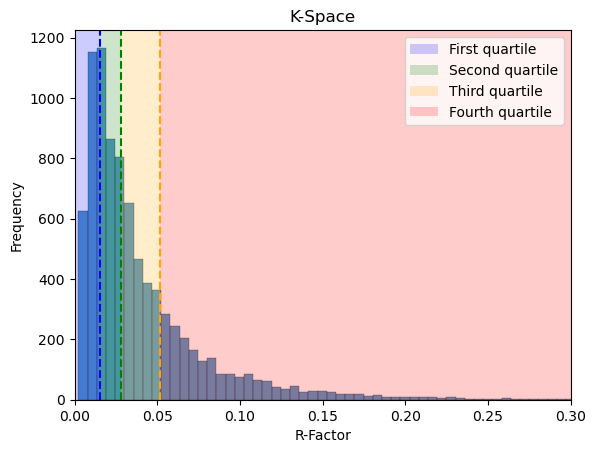

In [8]:
# Histogram K-space (MAE)
df_pred_mae_k = pd.DataFrame.from_dict(metrics_dict_k)
# Histogram
ax = sns.histplot(data=df_pred_mae_k, x="r_factor", kde=False)
# First quartile
ax.axvline(x=quantiles_mae_k[0], linestyle="dashed", color="blue")
ax.axvspan(xmin=0, xmax=quantiles_mae_k[0], facecolor="blue", alpha=0.2, label="First quartile")
# Second quartile
ax.axvline(x=quantiles_mae_k[1], linestyle="dashed", color="green")
ax.axvspan(xmin=quantiles_mae_k[0], xmax=quantiles_mae_k[1], facecolor="green", alpha=0.2, label="Second quartile")
# Third quartile
ax.axvline(x=quantiles_mae_k[2], linestyle="dashed", color="orange")
ax.axvspan(xmin=quantiles_mae_k[1], xmax=quantiles_mae_k[2], facecolor="orange", alpha=0.2, label="Third quartile")
# Fourth quartile
ax.axvspan(xmin=quantiles_mae_k[2], xmax=50, facecolor="red", alpha=0.2, label="Fourth quartile")
# Plot
plt.title("K-Space")
plt.xlim(0.0, 0.3)
plt.xlabel("R-Factor")
plt.ylabel("Frequency")
plt.legend()
plt.savefig("./plot_histogram_kspace_rfactor.svg")

### **1.2) R-Space Histogram**

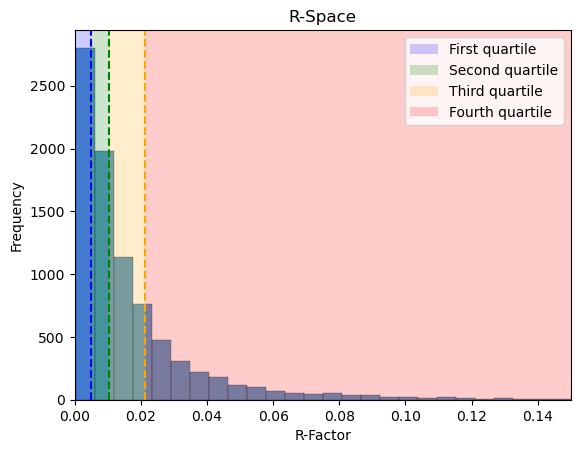

In [9]:
# Histogram R-space (MAE)
df_pred_mae_r = pd.DataFrame.from_dict(metrics_dict_r)
# Histogram
ax = sns.histplot(data=df_pred_mae_r, x="r_factor")
# First quartile
ax.axvline(x=quantiles_mae_r[0], linestyle="dashed", color="blue")
ax.axvspan(xmin=0, xmax=quantiles_mae_r[0], facecolor="blue", alpha=0.2, label="First quartile")
# Second quartile
ax.axvline(x=quantiles_mae_r[1], linestyle="dashed", color="green")
ax.axvspan(xmin=quantiles_mae_r[0], xmax=quantiles_mae_r[1], facecolor="green", alpha=0.2, label="Second quartile")
# Third quartile
ax.axvline(x=quantiles_mae_r[2], linestyle="dashed", color="orange")
ax.axvspan(xmin=quantiles_mae_r[1], xmax=quantiles_mae_r[2], facecolor="orange", alpha=0.2, label="Third quartile")
# Fourth quartile
ax.axvspan(xmin=quantiles_mae_r[2], xmax=50, facecolor="red", alpha=0.2, label="Fourth quartile")
# Plot
plt.title("R-Space")
plt.xlim(0, 0.15)
plt.xlabel("R-Factor")
plt.ylabel("Frequency")
plt.legend()
plt.savefig("./plot_histogram_rspace_rfactor.svg")

## **2.0) Grid of samples for Transition Metal Complexes**

In [10]:
# General metrics pandas df
df_tmqm = pd.DataFrame.from_dict(metrics_dict_k)

# Re-define quartiles for only molecular species
quantiles_mae_k = np.quantile(df_tmqm["mae"], [0.25, 0.50, 0.75])

In [11]:
# Classify ids depending on metrics
id_list = df_tmqm["id"]
mae_list = df_tmqm["mae"]

first_q = [x for x, mae in zip(id_list, mae_list) if mae <= quantiles_mae_k[0]]
second_q = [x for x, mae in zip(id_list, mae_list) if quantiles_mae_k[0] <= mae <= quantiles_mae_k[1]]
third_q = [x for x, mae in zip(id_list, mae_list) if quantiles_mae_k[1] <= mae <= quantiles_mae_k[2]]
fourth_q = [x for x, mae in zip(id_list, mae_list) if quantiles_mae_k[2] <= mae <= max(df_tmqm["r_factor"])]

In [12]:
# Structuring pred results for grid sampling
def get_samples(pred_data):
    # empty dictionary
    samples_dict = {}
    # loop over test data
    for n in range(len(pred_data)):
        # General info
        label = pred_data[n]["id"]
        # K-space
        target_chi = np.array(pred_data[n]["target_chi"])
        pred_chi = np.array(pred_data[n]["pred_chi"])
        target_k = np.array(pred_data[n]["target_k"])
        target_k_arr = get_array(target_k, target_chi)
        pred_k_arr = get_array(target_k, pred_chi)
        # R-space
        target_chir_mag = np.array(pred_data[n]["target_chir_mag"])
        pred_chir_mag = np.array(pred_data[n]["pred_chir_mag"])
        target_r = np.array(pred_data[n]["target_r"])
        pred_r = np.array(pred_data[n]["pred_r"])
        target_r_arr = get_array(target_r, target_chir_mag)
        pred_r_arr = get_array(pred_r, pred_chir_mag)
        # Append
        samples_dict.update({label: {"target_k": target_k_arr, 
                                     "pred_k": pred_k_arr,
                                     "target_r": target_r_arr,
                                     "pred_r": pred_r_arr}})
    return samples_dict

# Random sampler to re-build samples_dict with quartiles
def random_sampler(samples_dict, quartiles=[first_q, second_q, third_q, fourth_q], k=6):
    random_samples_dict = {}
    for idx, q in enumerate(quartiles):
        q_clean = remove_duplicates(q)
        random_mpids = random.sample(q_clean, k=k)
        for random_mpid in random_mpids:
            sample = samples_dict[random_mpid]
            random_samples_dict.update({random_mpid: sample})
    return random_samples_dict

### **2.1) Grid K-space**

In [13]:
# Get samples dict
samples_dict_mol = get_samples(pred_data=pred_data)

# Random sampling from samples_dict
samples_dict_mol = random_sampler(samples_dict_mol)

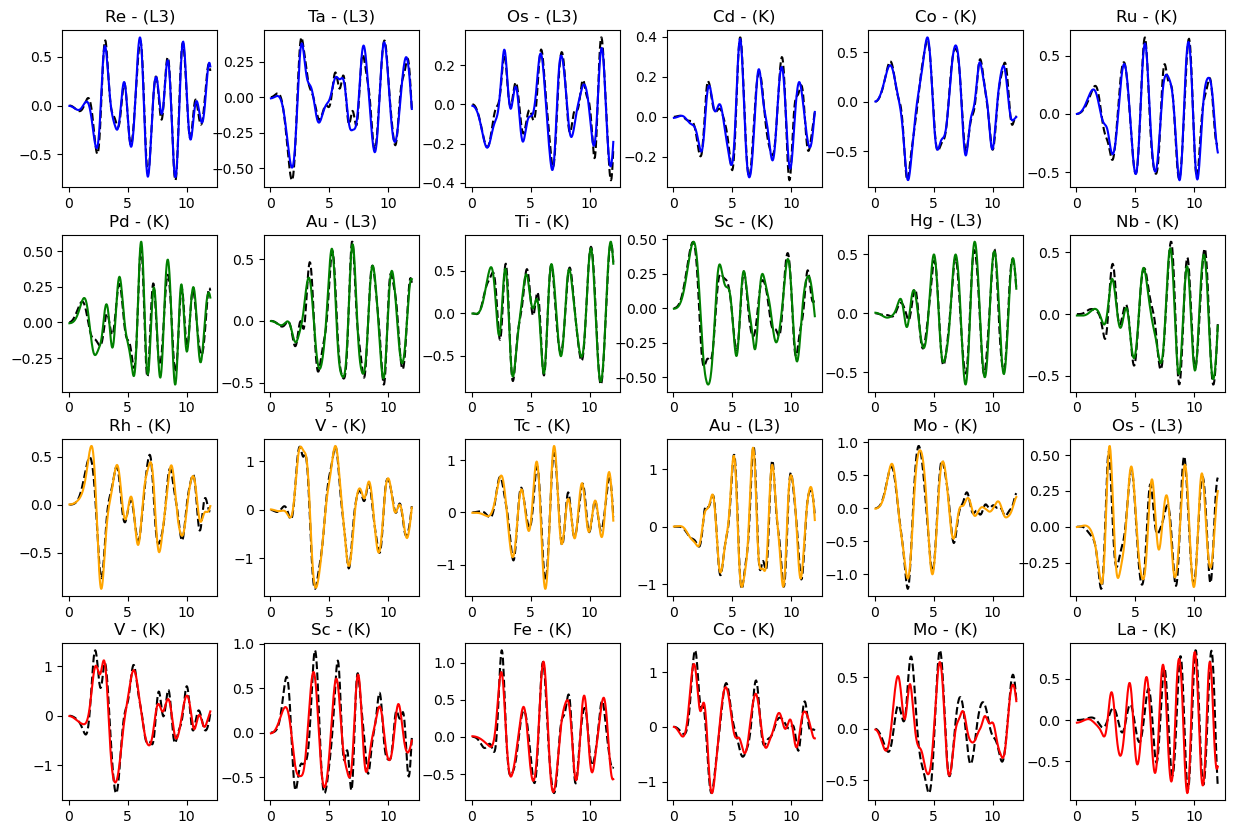

In [14]:
# PLOT K-space
fig, axs = plt.subplots(4, 6, figsize=(15, 10))
fig.subplots_adjust(hspace=0.3, wspace=0.3)

colors = [["blue"]*6, ["green"]*6, ["orange"]*6, ["red"]*6]
colors = [j for i in colors for j in i]

for idx, (ax, mp_id) in enumerate(zip(axs.flatten(), samples_dict_mol.keys())):
    elm = mp_id.split("_")[1]
    edge = mp_id.split("_")[2]
    ax.set_title(f"{elm} - ({edge})")
    ax.plot(samples_dict_mol[mp_id]["target_k"][:,0], samples_dict_mol[mp_id]["target_k"][:,1], "k--")
    ax.plot(samples_dict_mol[mp_id]["pred_k"][:,0], samples_dict_mol[mp_id]["pred_k"][:,1], color=colors[idx])

plt.savefig("./plot_kspaces.svg")

### **2.2) Grid R-space**

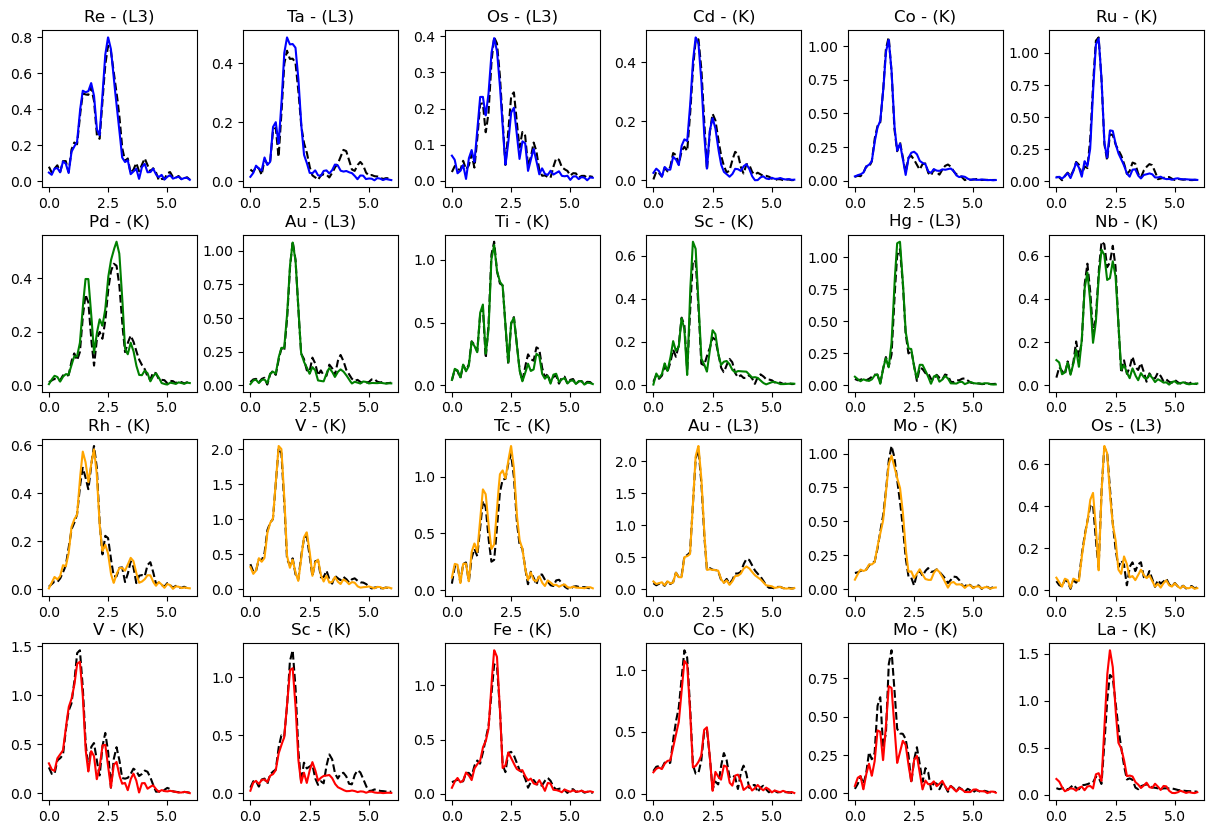

In [15]:
# PLOT R-space
fig, axs = plt.subplots(4, 6, figsize=(15, 10))
fig.subplots_adjust(hspace=0.3, wspace=0.3)

colors = [["blue"]*6, ["green"]*6, ["orange"]*6, ["red"]*6]
colors = [j for i in colors for j in i]

for idx, (ax, mp_id) in enumerate(zip(axs.flatten(), samples_dict_mol.keys())):
    elm = mp_id.split("_")[1]
    edge = mp_id.split("_")[2]
    ax.set_title(f"{elm} - ({edge})")
    ax.plot(samples_dict_mol[mp_id]["target_r"][:,0], samples_dict_mol[mp_id]["target_r"][:,1], "k--")
    ax.plot(samples_dict_mol[mp_id]["pred_r"][:,0], samples_dict_mol[mp_id]["pred_r"][:,1], color=colors[idx])
plt.savefig("./plot_rspaces.svg")

In [16]:
import pickle

with open("./test_samples_dict_mol.pkl", "wb") as p_file:
    pickle.dump(samples_dict_mol, p_file)
p_file.close()

## **3.0) Average Error per Metal Center**

In [17]:
from pymatgen.core import Element

In [18]:
def get_metal(mol_id):
    return mol_id.split("_")[1]
 
df = pd.DataFrame({
    "metal":      [get_metal(i) for i in metrics_dict_k["id"]],
    "r_factor_k": metrics_dict_k["r_factor"],
    "r_factor_r": metrics_dict_r["r_factor"],
})
 
df_avg = (df.groupby("metal")
            .agg(r_factor_k=("r_factor_k", "mean"),
                 r_factor_r=("r_factor_r", "mean"),
                 count     =("r_factor_k", "count")))
 
# Sort by atomic number Z
df_avg["Z"] = [Element(m).Z for m in df_avg.index]
df_avg = df_avg.sort_values("Z").drop(columns="Z")

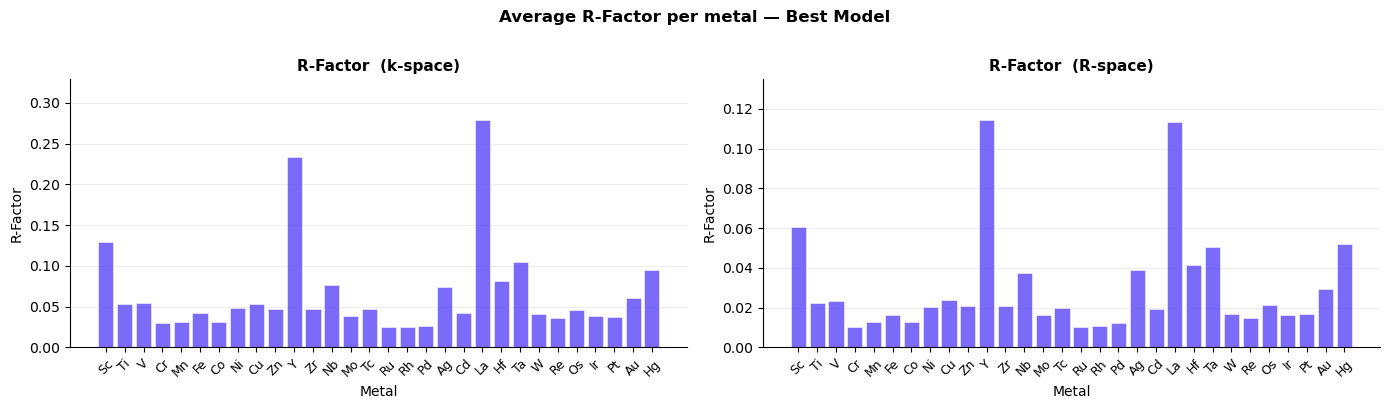

In [19]:
metrics = [
    ("r_factor_k", "R-Factor  (k-space)"),
    ("r_factor_r", "R-Factor  (R-space)"),
]
 
metals = df_avg.index.tolist()
 
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
 
for ax, (col, title) in zip(axes, metrics):
    vals = df_avg[col]
    bars = ax.bar(metals, vals,
                  color="#4F39F6", alpha=0.75,
                  edgecolor="white", linewidth=0.5, zorder=2)
 
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Metal")
    ax.set_ylabel("R-Factor")
    ax.tick_params(axis="x", rotation=45, labelsize=9)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.yaxis.grid(True, lw=0.5, color="0.9", zorder=0)
    sns.despine(ax=ax)
 
plt.suptitle("Average R-Factor per metal — Best Model",
             fontsize=12, fontweight="bold", y=1.01)

plt.tight_layout()
plt.show()